In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from adjustText import adjust_text

In [ ]:
pth = os.path.join('..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'development', 'modeling')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out = os.path.join(pth, 'figures', 'mesencoder', 'magnitude')

In [3]:
fn = os.path.join(pth_data, 'summary.csv')
names_dict = pd.read_csv(fn, index_col = 0).Name.to_dict()

In [4]:
fn = os.path.join(pth_feat, 'union.csv')
g = pd.read_csv(fn).mmusculus.drop_duplicates()

In [5]:
adata = sc.read_h5ad(os.path.join(pth_in, 'trajectories.h5ad'))
adata = sc.get.aggregate(adata, 'source', 'mean')[:, g].copy()
adata

AnnData object with n_obs × n_vars = 3 × 237
    obs: 'source'
    layers: 'mean'

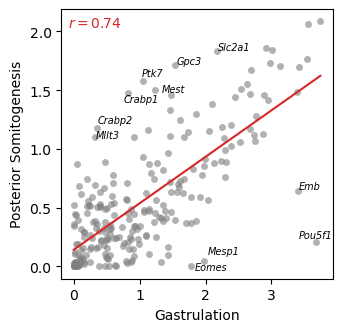

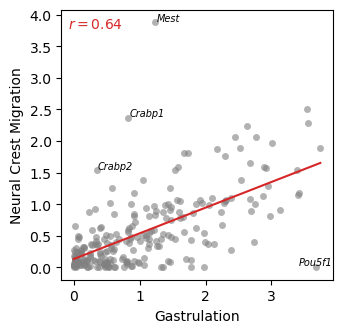

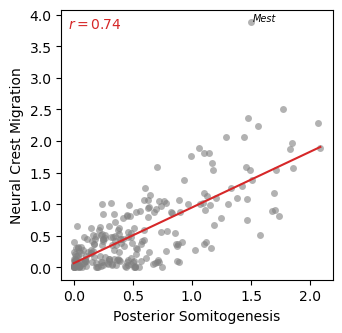

In [ ]:
# compare gene expression strength (pairwise)
for xvar, yvar, n in (
    ('GSE162534', 'GSE229103', 11),
    ('GSE162534', 'rRNAModifications', 4),
    ('GSE229103', 'rRNAModifications', 1)):

    # OLS regression
    xx = adata[xvar].layers['mean'].flatten()
    yy = adata[yvar].layers['mean'].flatten()
    m, b = np.polyfit(xx, yy, 1)
    ols_pred = lambda x: m * x + b
    rval = np.corrcoef(xx, yy)[0, 1].round(2)

    # compute residuals
    res = pd.Series(yy - ols_pred(xx),
                    index = adata.var_names)
    res.sort_values(key = abs, inplace = True,
                    ascending = False)

    # plot gene expression strength (scatter)
    fig, ax = plt.subplots(1, 1, figsize = (3.5, 3.5))
    ax.scatter(xx, yy, s = 25, alpha = .6, linewidth = 0,
               c = 'grey', label = 'Mean Expression')

    # plot OLS regression fit (line)
    xx_ols = np.asarray([xx.min(), xx.max()])
    ax.plot(xx_ols, ols_pred(xx_ols), c = 'tab:red',
            label = 'OLS fit')

    # label outliers
    texts = list()
    for lbl in res.head(n).index:
        ix = adata.var_names.get_indexer([lbl])
        texts.append(ax.text(
            xx[ix], yy[ix], lbl,
            fontsize = 7,
            fontstyle = 'italic'))
    adjust_text(texts = texts)

    ax.text(.025, .975, r'$r=$' + f'{rval}',
            transform = ax.transAxes,
            fontsize = 10, color = 'tab:red',
            ha = 'left', va = 'top')

    ax.set_xlabel(names_dict[xvar])
    ax.set_ylabel(names_dict[yvar])
    fn = os.path.join(pth_out, f'X__{xvar}_v_{yvar}.pdf')
    plt.savefig(fn, bbox_inches = 'tight')

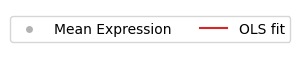

In [ ]:
fig, lax = plt.subplots(1, 1, figsize = (1, .5))
lax.legend(*ax.get_legend_handles_labels(), ncol = 2)
lax.axis(False)
fn = os.path.join(pth_out, 'X_legend.pdf')
plt.savefig(fn, bbox_inches = 'tight')